C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 2 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 91 2025    QLP     200   117831881      0.0
  1 TESS Sector 92 2025    QLP     200   117831881      0.0
  S91: CBV no aplicado (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.)
  S91: 2 segmentos/órbitas | picos superiores removidos: 95 de 7531
  S92: CBV no aplicado (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.)
  S92: 2 segmentos/órbitas | picos superiores removidos: 111 de 8614

[ANTES de limpiar en fase] N=15939, baseline=52.81 d
  LS : P = 1.843799 d (2xP = 3.687598 d), potencia = 0.3205, FAP = 0.00e+00
  PDM: P = 1.837384 d (2xP = 3.674767 d), theta_min = 0.2252, FAP ~ 0.010 (mínimo resoluble 1/101)


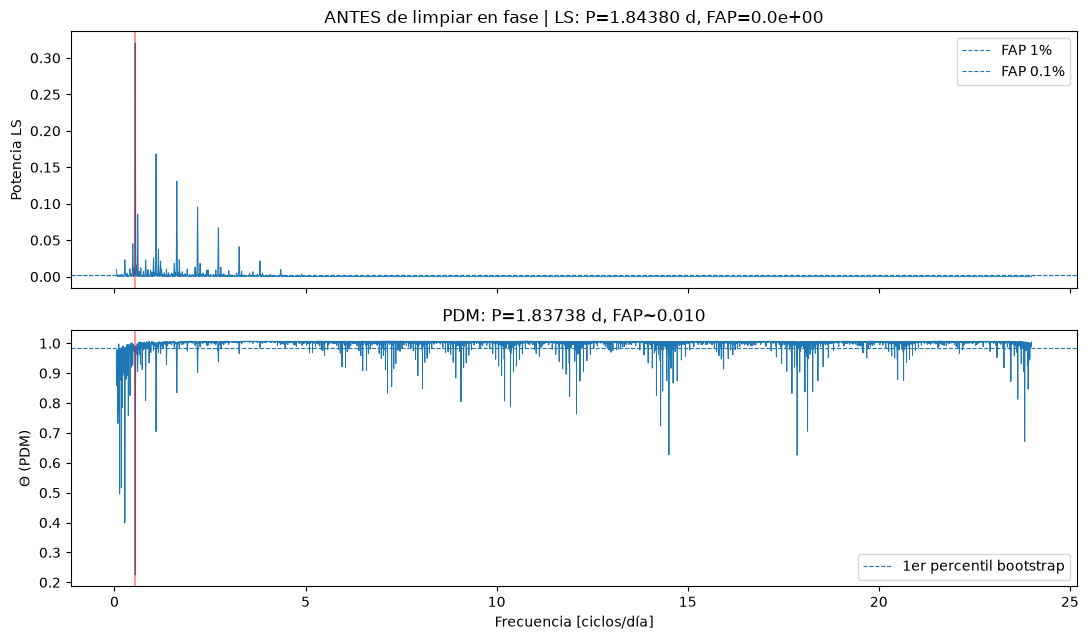


Periodo PDM fino inicial: P = 3.678535 d | T0 = 3775.44745

O-C: 18 eclipses medidos (8 primarios, 10 secundarios), 4 discrepantes
  P_OC = 3.678555 +- 0.000322 d   (P_PDM fino: 3.678535 d)
  dispersión del O-C (buenos) = 6.7 min
  descartado por O-C: secundario BTJD 3777.267, O-C = -27.1 min
  descartado por O-C: secundario BTJD 3792.013, O-C = +17.8 min
  descartado por O-C: secundario BTJD 3810.374, O-C = -27.0 min
  descartado por O-C: secundario BTJD 3825.124, O-C = +24.2 min


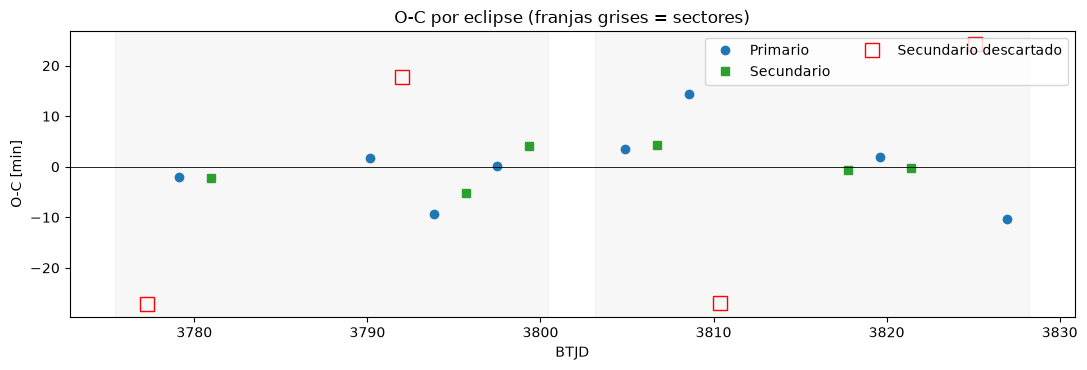

Periodo adoptado para el plegado y limpieza: P = 3.678535 d

[Análisis por Ciclo Orbital] Total ciclos: 14 | Ciclos descartados completos: 1
  Ciclo   7 (BTJD ~ 3802.96): DESCARTADO (RMS_ciclo=0.0080>0.0064)


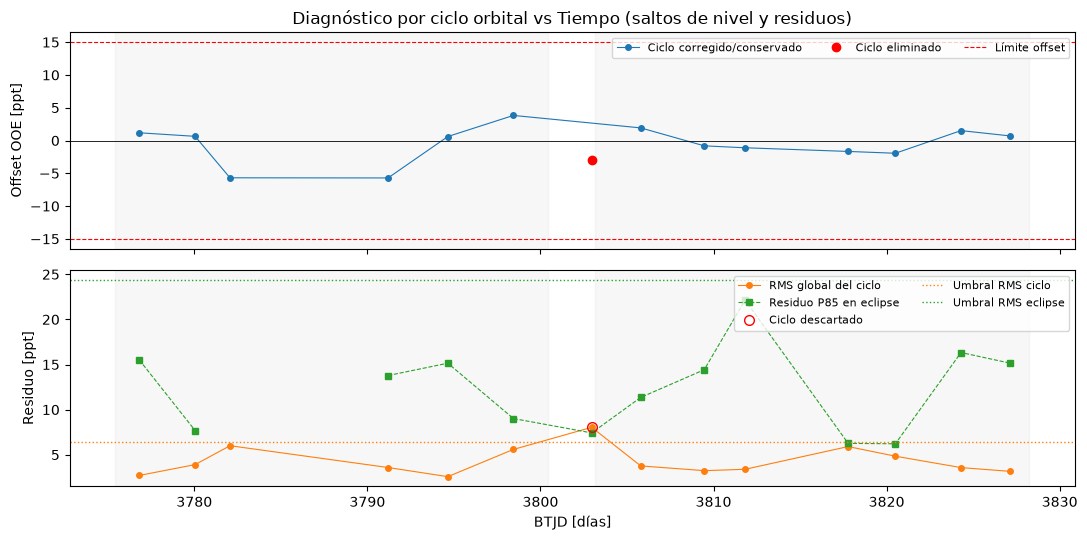

Periodo re-afinado tras nivelar ciclos: P = 3.678619 d

[Normalización por eclipse] 21 eclipses | descartados: 7 (3480 puntos)
  primario   ciclo   0 (BTJD ~ 3775.78): DESCARTADO (incompleto)
  primario   ciclo  10 (BTJD ~ 3811.93): DESCARTADO (incompleto)
  primario   ciclo  13 (BTJD ~ 3823.30): DESCARTADO (incompleto)
  secundario ciclo   0 (BTJD ~ 3777.26): DESCARTADO (desfase=-24.0 min)
  secundario ciclo   4 (BTJD ~ 3791.98): DESCARTADO (s=1.188)
  secundario ciclo   9 (BTJD ~ 3810.40): DESCARTADO (desfase=-26.5 min)
  secundario ciclo  13 (BTJD ~ 3825.09): DESCARTADO (desfase=+24.0 min)
  Aceptados: s = 0.960 (rango 0.873-1.144) | nivel a-1 = -2.53 ppt | desfase = -0.0 min (+-5.9)
  Dispersión robusta dentro de eclipses: 4.22 ppt (antes) -> 3.77 ppt (después)


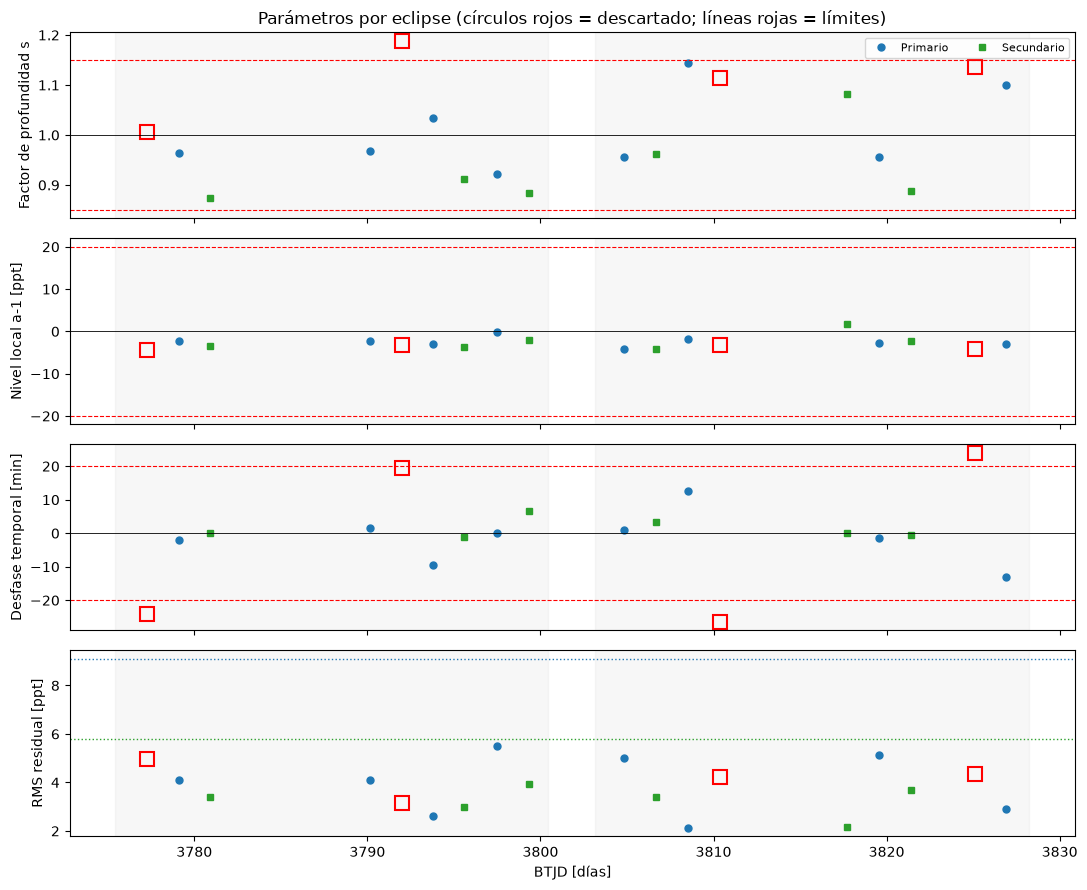

  iteración 1: 764 puntos fuera de plantilla (+764 en este paso; 194 en ventana de eclipse)
  iteración 2: 922 puntos fuera de plantilla (+158 en este paso; 223 en ventana de eclipse)
  iteración 3: 990 puntos fuera de plantilla (+68 en este paso; 241 en ventana de eclipse)
  iteración 4: 1017 puntos fuera de plantilla (+27 en este paso; 244 en ventana de eclipse)
  iteración 5: 1037 puntos fuera de plantilla (+20 en este paso; 245 en ventana de eclipse)
  iteración 6: 1040 puntos fuera de plantilla (+4 en este paso; 245 en ventana de eclipse)
  iteración 7: 1044 puntos fuera de plantilla (+4 en este paso; 245 en ventana de eclipse)
  iteración 8: 1043 puntos fuera de plantilla (+0 en este paso; 245 en ventana de eclipse)

================ RESUMEN DE LIMPIEZA ================
Total puntos iniciales (tras reducción base): 15939
  - Removidos por ciclo orbital anómalo : 399 (2.50 %)
  - Removidos por eclipse individual    : 3480 (21.83 %)
  - Removidos por eclipse desfasado O-C : 0 (0.00

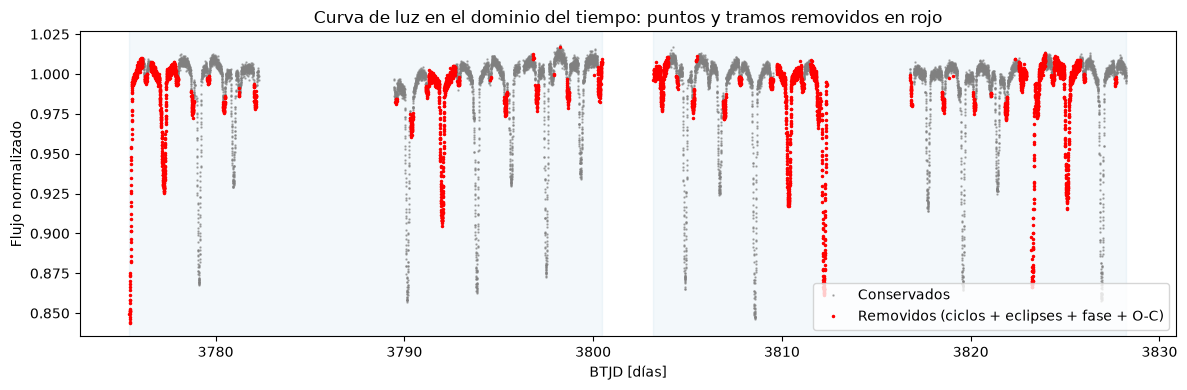

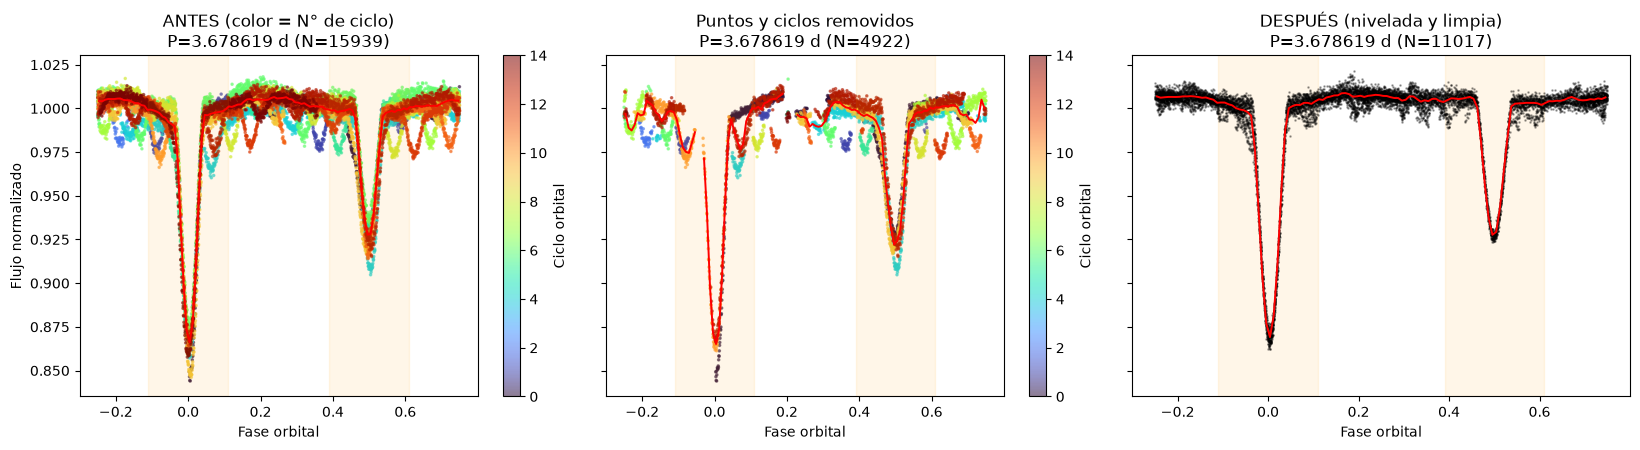

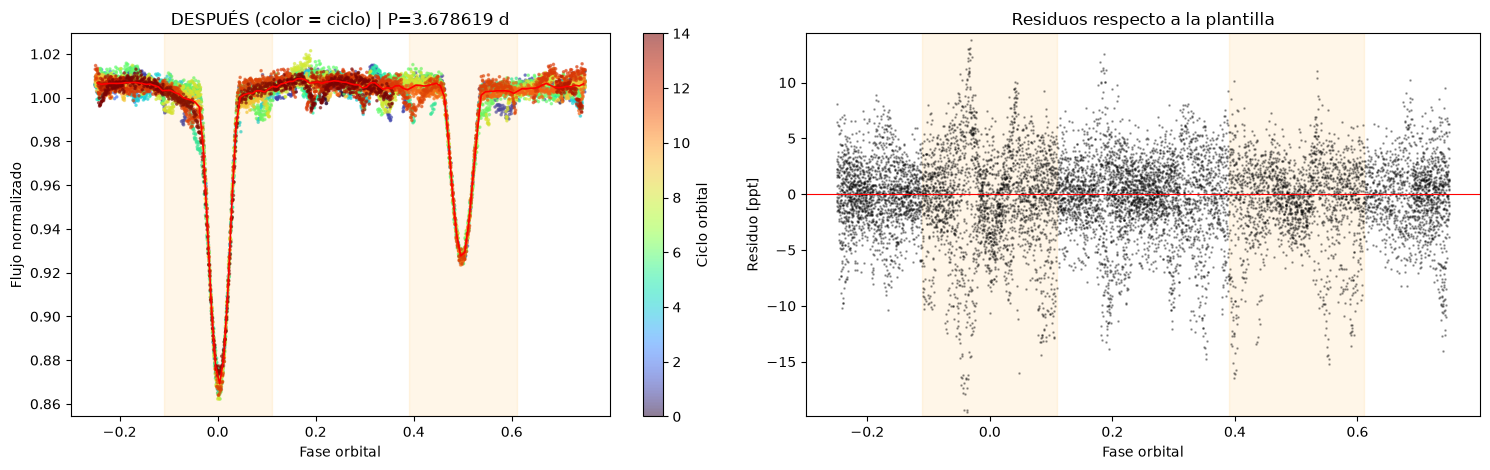


[DESPUÉS de limpiar en fase] N=11017, baseline=52.12 d
  LS : P = 1.841289 d (2xP = 3.682578 d), potencia = 0.3094, FAP = 0.00e+00
  PDM: P = 1.841289 d (2xP = 3.682578 d), theta_min = 0.1860, FAP ~ 0.010 (mínimo resoluble 1/101)


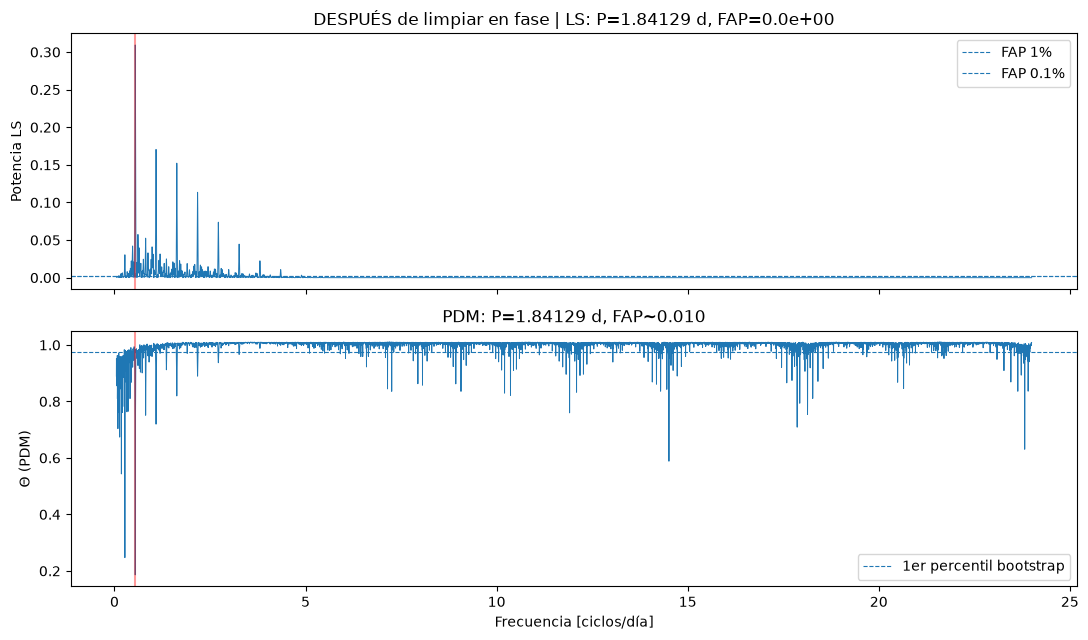

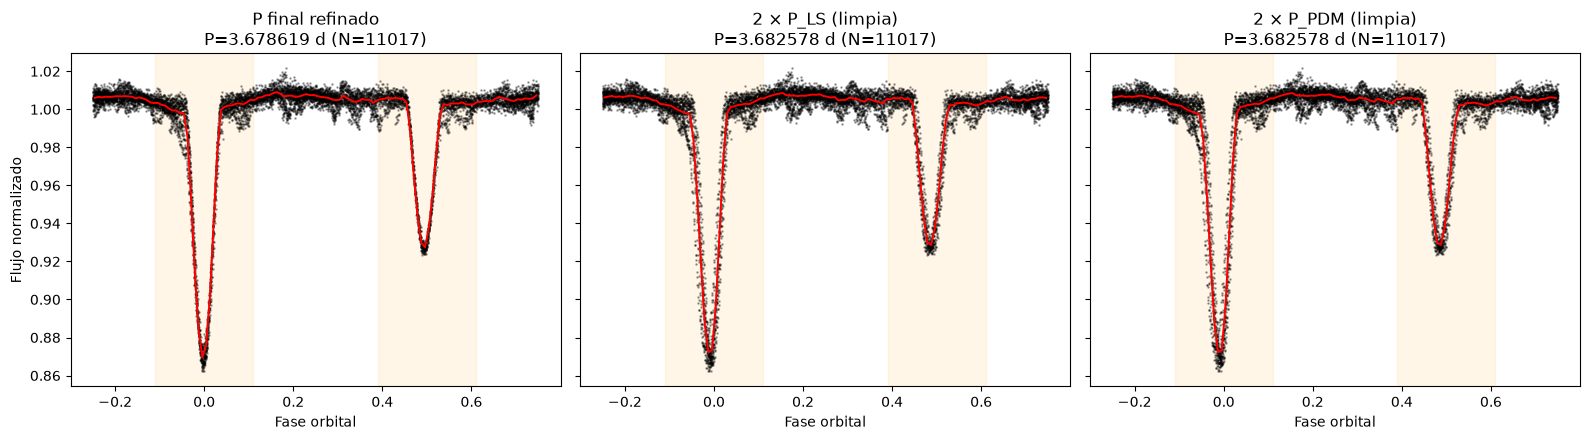

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from astropy.timeseries import LombScargle
from scipy.ndimage import median_filter

# ======================= PARÁMETROS CONFIGURABLES =======================
TIC = "TIC 117831881"
SECTORES = ["TESS Sector 91", "TESS Sector 92"]
SEED = 42

# --- 1. Reducción base (dominio del tiempo) ---
VENTANA_DIAS = 0.5            # ventana de la mediana móvil para picos superiores
SIGMA_SUP_TIEMPO = 3.5        # SOLO recorte superior (flares/rayos cósmicos)
GAP_DIAS = 0.4                # salto temporal que define un nuevo segmento/órbita TESS

# --- 2. Periodogramas ---
FMIN, FMAX = 0.05, 24.0       # rango de frecuencias [ciclos/día]
OVERSAMPLE = 10
BIN_MIN = 20                  # binning (min) para acelerar PDM global y su bootstrap
PDM_NBINS = 20
N_BOOT = 100                  # iteraciones bootstrap para FAP de PDM

# --- 3. Periodo y ventanas de fase ---
P_MANUAL = None               # None = FACTOR_PERIODO * P_LS refinado con PDM fino
FACTOR_PERIODO = 2            # 2 para binarias eclipsantes simétricas/casi-simétricas
REFINAR_PERIODO = True        # afina P con PDM de alta resolución (+-0.5 %)
USAR_P_OC = False             # True: usa P de medir_oc; False: conserva P_PDM fino (más estable ante asimetrías)

# IMPORTANTE: el secundario de tu gráfico cae en ~0.50 (no en 0.47). Las ventanas quedaron
# centradas en 0.50 con el mismo semiancho (0.11) que el primario.
PROTEGER_FASE = [(-0.11, 0.11), (0.39, 0.61)]

# --- 4. Análisis por eclipse (O-C) ---
HALF_WIN_FASE = 0.10          # semiancho (en fase) de la ventana de cada eclipse
SEC_FASE = 0.50               # fase aproximada del eclipse secundario
OC_RANGO_D = 0.25             # rango de búsqueda gruesa de desfase [días]
OC_SIGMA = 3.0                # umbral (en MAD robusto) para descartar un eclipse desfasado
OC_MIN_D = 0.004              # piso mínimo de tolerancia O-C (~5.8 min)

# --- 5. Detección y corrección por CICLO ORBITAL (clave contra ramas superpuestas) ---
CORREGIR_OFFSET_CICLO = True  # True: alinea la mediana fuera de eclipse (OOE) de cada ciclo a 1.0
CORREGIR_RAMPA_CICLO = True   # True: quita inclinación lineal suave por ciclo usando solo puntos OOE
MAX_OFFSET_CORREGIBLE = 0.015 # offset OOE máximo tolerable (1.5%); si supera esto, el ciclo se ELIMINA
SIGMA_RMS_CICLO = 2.5         # umbral (en MAD robusto de los RMS de todos los ciclos) para eliminar un ciclo ruidoso
SIGMA_ECL_CICLO = 2.8         # umbral de residuo específico DENTRO de los eclipses para cazar ramas fantasma
MIN_PUNTOS_OOE_CICLO = 15     # mínimo de puntos fuera de eclipse para estimar offset de un ciclo

# --- 6. NUEVO: normalización y alineación POR ECLIPSE ---
# Cada eclipse (primario o secundario de cada ciclo) se ajusta a la plantilla con
#     y = a + b*tau + s * (M(fase - d/P) - 1)
# a, b : nivel y pendiente locales (línea base medida en los flancos fuera de eclipse)
# s    : factor de profundidad (absorbe dilución/contaminación distinta entre órbitas o sectores)
# d    : desfase temporal del eclipse
# Los eclipses que no se pueden llevar a la plantilla con parámetros razonables se descartan.
NORMALIZAR_ECLIPSES = True
ESCALAR_PROFUNDIDAD = True    # False si sospechas que las diferencias de profundidad son físicas (manchas)
ALINEAR_TIEMPO_ECLIPSE = True # el desfase se usa solo para fase/limpieza/gráficos; los tiempos del FITS NO se tocan
FLANCO_FASE = 0.08            # ancho (en fase) de los tramos fuera de eclipse a cada lado de la ventana
MIN_PTS_FLANCO = 10           # mínimo de puntos en cada flanco para fijar la línea base
MIN_COBERTURA = 0.7           # fracción mínima de la ventana de eclipse con datos
DESCARTAR_INCOMPLETOS = True  # True: elimina eclipses cortados por huecos (suelen ser los peores)
DESFASE_MAX_MIN = 20.0        # |desfase| máximo aceptable por eclipse [min]
ESCALA_MIN, ESCALA_MAX = 0.85, 1.15   # rango aceptable del factor de profundidad
BASE_MAX = 0.02               # |a - 1| máximo aceptable (nivel local)
N_ITER_ECL = 3                # iteraciones plantilla <-> parámetros por eclipse
SIGMA_ECL_INDIV = 3.0         # umbral (MAD robusto entre eclipses del mismo tipo) del RMS residual tras normalizar
RMS_ECL_MIN = 0.0008          # piso del MAD del RMS (evita descartar de más si todos son parecidos)

# --- 7. Limpieza iterativa en fase (punto a punto tras limpiar ciclos y eclipses) ---
FASE_NBINS = 160              # bins de fase para construir la plantilla mediana/MAD
K_INF, K_SUP = 2.8, 3.0       # umbrales sigma fuera de eclipse (más estrictos para dejar 1 sola rama delgada)
K_ECLIPSE_EXTREMO = 4.0       # umbral DENTRO de PROTEGER_FASE (antes 5.5; ahora es viable porque los eclipses ya están alineados)
N_ITER = 8


# ======================= 1) DESCARGA Y REDUCCIÓN BASE =======================
def descargar():
    sr = lk.search_lightcurve(TIC, author="QLP")
    sr = sr[np.isin(sr.mission, SECTORES)]
    print(sr)
    return sr.download_all(quality_bitmask="hard", flux_column="sap_flux")


def cotrending_cbv(lc):
    try:
        cbvc = lk.correctors.CBVCorrector(lc)
        cbvc.correct(cbv_type=["SingleScale", "Spike"],
                     cbv_indices=[np.arange(1, 9), "ALL"])
        print(f"  S{lc.meta.get('SECTOR')}: CBV aplicado")
        return cbvc.corrected_lc
    except Exception as e:
        print(f"  S{lc.meta.get('SECTOR')}: CBV no aplicado ({type(e).__name__}: {e})")
        return lc


def clip_superior_y_nivelar_segmentos(lc):
    """
    1) Recorta SOLO picos superiores por segmento (separados por GAP_DIAS).
    2) Nivela cada órbita de TESS con su percentil 70 (aproxima el continuo fuera de eclipse
       mejor que la mediana global, evitando saltos de nivel entre órbitas del mismo sector).
    """
    t = np.asarray(lc.time.value, dtype=np.float64)
    f = np.asarray(lc.flux.value, dtype=np.float64)
    dt = np.nanmedian(np.diff(t))
    n = int(VENTANA_DIAS / dt) | 1

    cortes = np.where(np.diff(t) > GAP_DIAS)[0] + 1
    ini = np.r_[0, cortes]
    fin = np.r_[cortes, len(t)]

    tend = np.empty_like(f)
    f_niv = np.empty_like(f)
    for a, b in zip(ini, fin):
        seg = f[a:b]
        # Nivelación preliminar por órbita TESS usando percentil 70 (inmune a los eclipses)
        nivel_seg = np.nanpercentile(seg, 70)
        seg_norm = seg / nivel_seg
        f_niv[a:b] = seg_norm
        tend[a:b] = median_filter(seg_norm, size=min(n, (b - a) | 1), mode="nearest")

    resid = f_niv - tend
    sig = 1.4826 * np.nanmedian(np.abs(resid - np.nanmedian(resid)))
    buenos = resid < SIGMA_SUP_TIEMPO * sig
    print(f"  S{lc.meta.get('SECTOR')}: {len(ini)} segmentos/órbitas | "
          f"picos superiores removidos: {(~buenos).sum()} de {len(lc)}")

    lc_out = lc[buenos].copy()
    lc_out.flux = f_niv[buenos] * lc_out.flux.unit
    if lc_out.flux_err is not None:
        err_val = np.asarray(lc.flux_err.value, dtype=np.float64)[buenos]
        lc_out.flux_err = (err_val / np.nanmedian(f)) * lc_out.flux.unit
    return lc_out


def reducir_base(lc):
    lc = lc.remove_nans()
    lc = lc[lc.quality == 0]
    lc = cotrending_cbv(lc).remove_nans()
    lc = clip_superior_y_nivelar_segmentos(lc)
    return lc


# ======================= 2) PERIODOGRAMAS =======================
def bin_tiempo(t, y, minutos):
    w = minutos / 1440.0
    k = np.floor((t - t.min()) / w).astype(int)
    cnt = np.bincount(k)
    ok = cnt > 0
    tb = np.bincount(k, weights=t)[ok] / cnt[ok]
    yb = np.bincount(k, weights=y)[ok] / cnt[ok]
    return tb, yb


def pdm_theta(t, y, freqs, nbins=PDM_NBINS):
    var = np.var(y, ddof=1)
    theta = np.empty(len(freqs))
    for i, f in enumerate(freqs):
        idx = (((t * f) % 1.0) * nbins).astype(int)
        cnt = np.bincount(idx, minlength=nbins)
        s1 = np.bincount(idx, weights=y, minlength=nbins)
        s2 = np.bincount(idx, weights=y * y, minlength=nbins)
        ok = cnt > 1
        ss = (s2[ok] - s1[ok] ** 2 / cnt[ok]).sum()
        dof = (cnt[ok] - 1).sum()
        theta[i] = (ss / dof) / var
    return theta


def analizar(t, y, titulo):
    baseline = t.max() - t.min()
    freq = np.arange(FMIN, FMAX, 1.0 / (OVERSAMPLE * baseline))

    # Lomb-Scargle
    ls = LombScargle(t, y)
    power = ls.power(freq)
    i_ls = np.argmax(power)
    P_ls = 1.0 / freq[i_ls]
    fap_ls = ls.false_alarm_probability(power[i_ls], minimum_frequency=FMIN,
                                        maximum_frequency=FMAX, method="baluev")
    niveles = ls.false_alarm_level([0.01, 0.001], minimum_frequency=FMIN,
                                   maximum_frequency=FMAX, method="baluev")

    # PDM + FAP por bootstrap
    tb, yb = bin_tiempo(t, y, BIN_MIN)
    theta = pdm_theta(tb, yb, freq)
    i_pdm = np.argmin(theta)
    P_pdm = 1.0 / freq[i_pdm]
    rng = np.random.default_rng(SEED)
    min_boot = np.array([pdm_theta(tb, rng.permutation(yb), freq).min() for _ in range(N_BOOT)])
    fap_pdm = (np.sum(min_boot <= theta[i_pdm]) + 1) / (N_BOOT + 1)

    print(f"\n[{titulo}] N={len(t)}, baseline={baseline:.2f} d")
    print(f"  LS : P = {P_ls:.6f} d (2xP = {2*P_ls:.6f} d), potencia = {power[i_ls]:.4f}, FAP = {fap_ls:.2e}")
    print(f"  PDM: P = {P_pdm:.6f} d (2xP = {2*P_pdm:.6f} d), theta_min = {theta[i_pdm]:.4f}, FAP ~ {fap_pdm:.3f}"
          f" (mínimo resoluble 1/{N_BOOT + 1})")

    fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    axs[0].plot(freq, power, lw=0.7)
    for nv, lab in zip(niveles, ["FAP 1%", "FAP 0.1%"]):
        axs[0].axhline(nv, ls="--", lw=0.8, label=lab)
    axs[0].axvline(1 / P_ls, c="r", alpha=0.4)
    axs[0].set(ylabel="Potencia LS", title=f"{titulo} | LS: P={P_ls:.5f} d, FAP={fap_ls:.1e}")
    axs[0].legend(loc="upper right")

    axs[1].plot(freq, theta, lw=0.7)
    axs[1].axhline(np.percentile(min_boot, 1), ls="--", lw=0.8, label="1er percentil bootstrap")
    axs[1].axvline(1 / P_pdm, c="r", alpha=0.4)
    axs[1].set(xlabel="Frecuencia [ciclos/día]", ylabel=r"$\Theta$ (PDM)",
               title=f"PDM: P={P_pdm:.5f} d, FAP~{fap_pdm:.3f}")
    axs[1].legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    return dict(P_ls=P_ls, P_pdm=P_pdm, fap_ls=fap_ls, fap_pdm=fap_pdm)


def refinar_periodo(t, y, P0, frac=0.005, n=2000):
    """PDM fino con todos los puntos alrededor de P0 usando mayor resolución en fase."""
    freqs = (1.0 / P0) * (1 + np.linspace(-frac, frac, n))
    th = pdm_theta(t, y, freqs, nbins=80)
    return 1.0 / freqs[np.argmin(th)]


# ======================= 3) FUNCIONES DE FASE Y PLANTILLA =======================
def fase(t, P, t0):
    return ((t - t0) / P + 0.25) % 1.0 - 0.25          # [-0.25, 0.75)


def mascara_protegida(ph):
    prot = np.zeros(len(ph), dtype=bool)
    for a, b in PROTEGER_FASE:
        prot |= (ph >= a) & (ph <= b)
    return prot


def plantilla(ph, y, nb=FASE_NBINS):
    """Mediana y sigma robusto (MAD) por bin de fase."""
    idx = np.clip(((ph + 0.25) * nb).astype(int), 0, nb - 1)
    med = np.full(nb, np.nan)
    sig = np.full(nb, np.nan)
    for k in range(nb):
        v = y[idx == k]
        if len(v) >= 4:
            m = np.median(v)
            med[k] = m
            sig[k] = 1.4826 * np.median(np.abs(v - m))
    cen = (np.arange(nb) + 0.5) / nb - 0.25
    return cen, med, sig


def interp_periodica(ph, cen, valores):
    ok = np.isfinite(valores)
    c = np.r_[cen[ok] - 1.0, cen[ok], cen[ok] + 1.0]
    v = np.tile(valores[ok], 3)
    return np.interp(ph, c, v)


def epoca_minimo(t, y, P):
    """Tiempo del mínimo primario sobre la plantilla."""
    tref = t[0]
    cen, med, _ = plantilla(fase(t, P, tref), y, FASE_NBINS)
    i_min = np.nanargmin(med)
    return tref + cen[i_min] * P


# ======================= 4) O-C POR ECLIPSE =======================
def _plantilla_dt(xs, ys, W, nb=80):
    ok = np.abs(xs) <= W
    xs, ys = xs[ok], ys[ok]
    edges = np.linspace(-W, W, nb + 1)
    cen = 0.5 * (edges[:-1] + edges[1:])
    idx = np.clip(np.digitize(xs, edges) - 1, 0, nb - 1)
    med = np.array([np.median(ys[idx == k]) if np.any(idx == k) else np.nan for k in range(nb)])
    g = np.isfinite(med)
    return lambda x: np.interp(x, cen[g], med[g])


def medir_oc(t, y, P, t0):
    """
    Mide el instante central de cada eclipse primario y secundario, ajusta una efeméride
    lineal y marca como malos los eclipses que sufren desfase real o artefactos severos.
    """
    W = HALF_WIN_FASE * P
    dtc = np.nanmedian(np.diff(t))
    ev = []
    for tipo, f0 in ((0, 0.0), (1, SEC_FASE)):
        tc0 = t0 + f0 * P
        n_ini = int(np.floor((t.min() - tc0) / P)) - 1
        n_fin = int(np.ceil((t.max() - tc0) / P)) + 2
        for n in range(n_ini, n_fin):
            tc = tc0 + n * P
            m = np.abs(t - tc) <= W
            if m.sum() >= 0.75 * (2 * W / dtc):
                ev.append((tipo, n, tc, m))
    if len(ev) < 6:
        print("Pocos eclipses completos para O-C; se omite este paso.")
        return dict(P=P, t0=t0, perr=np.nan, malos=np.zeros(len(t), dtype=bool), T=None)

    tipo = np.array([e[0] for e in ev])
    nn = np.array([e[1] for e in ev], dtype=float)
    tcs = np.array([e[2] for e in ev])
    shifts = np.zeros(len(ev))
    grueso = np.linspace(-OC_RANGO_D, OC_RANGO_D, 241)
    fino = np.linspace(-0.003, 0.003, 61)

    for _ in range(3):
        tpl = {}
        for tp in (0, 1):
            if np.any(tipo == tp):
                xs = np.concatenate([t[e[3]] - e[2] - s for e, s in zip(ev, shifts) if e[0] == tp])
                ys = np.concatenate([y[e[3]] for e in ev if e[0] == tp])
                tpl[tp] = _plantilla_dt(xs, ys, W)
        for k, (tp, n, tc, m) in enumerate(ev):
            f, tm, ym = tpl[tp], t[m], y[m]
            sse = [np.sum((ym - f(tm - tc - s)) ** 2) for s in grueso]
            s0 = grueso[int(np.argmin(sse))]
            sse2 = [np.sum((ym - f(tm - tc - (s0 + d))) ** 2) for d in fino]
            shifts[k] = s0 + fino[int(np.argmin(sse2))]

    T = tcs + shifts
    A = np.c_[(tipo == 0).astype(float), (tipo == 1).astype(float), nn]
    pesos = np.where(tipo == 0, 1.0, 0.5)
    buenos = np.ones(len(T), dtype=bool)
    for _ in range(6):
        Aw = A[buenos] * pesos[buenos, None]
        Tw = T[buenos] * pesos[buenos]
        coef = np.linalg.lstsq(Aw, Tw, rcond=None)[0]
        oc = T - A @ coef
        sig = 1.4826 * np.median(np.abs(oc[buenos] - np.median(oc[buenos])))
        nuevo = np.abs(oc) <= OC_SIGMA * max(sig, OC_MIN_D)
        if np.array_equal(nuevo, buenos):
            break
        buenos = nuevo

    sig_fit = np.std(oc[buenos], ddof=min(3, buenos.sum() - 1))
    cov = sig_fit ** 2 * np.linalg.pinv(A[buenos].T @ A[buenos])
    P_new, perr = coef[2], float(np.sqrt(cov[2, 2]))

    print(f"\nO-C: {len(T)} eclipses medidos ({(tipo == 0).sum()} primarios, {(tipo == 1).sum()} secundarios), "
          f"{(~buenos).sum()} discrepantes")
    print(f"  P_OC = {P_new:.6f} +- {perr:.6f} d   (P_PDM fino: {P:.6f} d)")
    print(f"  dispersión del O-C (buenos) = {sig_fit * 1440:.1f} min")
    for k in np.where(~buenos)[0]:
        print(f"  descartado por O-C: {'primario' if tipo[k] == 0 else 'secundario'} "
              f"BTJD {T[k]:.3f}, O-C = {oc[k] * 1440:+.1f} min")

    malos = np.zeros(len(t), dtype=bool)
    for k in np.where(~buenos)[0]:
        malos |= ev[k][3]
    return dict(P=P_new, t0=coef[0], perr=perr, malos=malos, T=T, oc=oc, tipo=tipo, buenos=buenos)


def graf_oc(res, reducidas):
    if res["T"] is None:
        return
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for tp, mk, nom, col in ((0, "o", "Primario", "C0"), (1, "s", "Secundario", "C2")):
        s = res["tipo"] == tp
        b = s & res["buenos"]
        ax.plot(res["T"][b], res["oc"][b] * 1440, mk, c=col, label=nom)
        if np.any(s & ~res["buenos"]):
            ax.plot(res["T"][s & ~res["buenos"]], res["oc"][s & ~res["buenos"]] * 1440, mk,
                    c="r", mfc="none", ms=10, lw=1.5, label=f"{nom} descartado")
    for l in reducidas:
        ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
    ax.axhline(0, c="k", lw=0.6)
    ax.set(xlabel="BTJD", ylabel="O-C [min]", title="O-C por eclipse (franjas grises = sectores)")
    ax.legend(ncol=2)
    plt.tight_layout()
    plt.show()


# ======================= 5) DETECCIÓN Y NIVELACIÓN POR CICLO ORBITAL =======================
def procesar_por_ciclos(t, y, P, t0):
    """
    Evalúa cada ciclo orbital completo k = floor((t - t0 + 0.25*P) / P):
      1) Mide su offset vertical fuera de eclipse (OOE) y su rampa lineal OOE.
      2) Si el offset es moderado (<= MAX_OFFSET_CORREGIBLE), lo corrige para eliminar
         las ramas paralelas horizontales sin perder datos ni deformar eclipses.
      3) Calcula el RMS residual de cada ciclo respecto a la plantilla global (tanto
         fuera como dentro de PROTEGER_FASE).
      4) Marca como MALOS los ciclos completos que tengan saltos extremos o ramas
         fantasma (RMS global o en eclipse por encima del umbral robusto).
    """
    y_corr = y.copy()
    ph = fase(t, P, t0)
    prot = mascara_protegida(ph)
    ooe = ~prot  # puntos fuera de eclipse

    # Índice entero de ciclo orbital para cada punto
    ciclo_id = np.floor((t - t0) / P + 0.25).astype(int)
    ciclos_unicos = np.unique(ciclo_id)

    # Plantilla OOE base (cerca de 1.0)
    cen0, med0, _ = plantilla(ph, y_corr, FASE_NBINS)
    modelo0 = interp_periodica(ph, cen0, med0)

    offsets_ciclo = np.zeros(len(ciclos_unicos))
    t_medio_ciclo = np.zeros(len(ciclos_unicos))
    exceso_offset = np.zeros(len(ciclos_unicos), dtype=bool)

    # Paso A: Medir y corregir offset/rampa suave por ciclo usando SOLO puntos fuera de eclipse
    for i, c in enumerate(ciclos_unicos):
        m_c = (ciclo_id == c)
        t_medio_ciclo[i] = np.mean(t[m_c])
        m_ooe = m_c & ooe
        if m_ooe.sum() >= MIN_PUNTOS_OOE_CICLO:
            res_ooe = y_corr[m_ooe] - modelo0[m_ooe]
            off = np.nanmedian(res_ooe)
            offsets_ciclo[i] = off
            if np.abs(off) > MAX_OFFSET_CORREGIBLE:
                exceso_offset[i] = True
            elif CORREGIR_OFFSET_CICLO:
                if CORREGIR_RAMPA_CICLO and (t[m_ooe].max() - t[m_ooe].min() > 0.3 * P):
                    # Ajuste lineal robusto sobre puntos fuera de eclipse del ciclo
                    tc_norm = (t[m_ooe] - t_medio_ciclo[i]) / P
                    p1, p0 = np.polyfit(tc_norm, res_ooe, 1)
                    # Solo aplica rampa si es suave (evita sobreajuste)
                    if np.abs(p1) < MAX_OFFSET_CORREGIBLE:
                        y_corr[m_c] -= (p0 + p1 * ((t[m_c] - t_medio_ciclo[i]) / P))
                    else:
                        y_corr[m_c] -= off
                else:
                    y_corr[m_c] -= off

    # Paso B: Recalcular plantilla con los ciclos ya nivelados y medir RMS por ciclo
    ok_prelim = ~np.isin(ciclo_id, ciclos_unicos[exceso_offset])
    cen, med, sig = plantilla(ph[ok_prelim], y_corr[ok_prelim], FASE_NBINS)
    modelo = interp_periodica(ph, cen, med)
    res = y_corr - modelo

    rms_total = np.full(len(ciclos_unicos), np.nan)
    rms_ecl = np.full(len(ciclos_unicos), np.nan)

    for i, c in enumerate(ciclos_unicos):
        m_c = (ciclo_id == c)
        if m_c.sum() >= 10:
            # MAD robusto del residuo en todo el ciclo
            rms_total[i] = 1.4826 * np.nanmedian(np.abs(res[m_c]))
        m_ce = m_c & prot
        if m_ce.sum() >= 5:
            # Percentil 85 del error absoluto dentro de los eclipses (caza hombros y ramas desfasadas)
            rms_ecl[i] = np.nanpercentile(np.abs(res[m_ce]), 85)

    # Umbrales adaptativos entre todos los ciclos
    med_rms = np.nanmedian(rms_total)
    mad_rms = 1.4826 * np.nanmedian(np.abs(rms_total - med_rms))
    umb_rms = med_rms + SIGMA_RMS_CICLO * max(mad_rms, 0.0005)

    med_ecl = np.nanmedian(rms_ecl)
    mad_ecl = 1.4826 * np.nanmedian(np.abs(rms_ecl - med_ecl))
    umb_ecl = med_ecl + SIGMA_ECL_CICLO * max(mad_ecl, 0.0008)

    ciclo_malo = (
        exceso_offset
        | (rms_total > umb_rms)
        | (rms_ecl > umb_ecl)
    )

    keep_ciclo = ~np.isin(ciclo_id, ciclos_unicos[ciclo_malo])

    print(f"\n[Análisis por Ciclo Orbital] Total ciclos: {len(ciclos_unicos)} | "
          f"Ciclos descartados completos: {ciclo_malo.sum()}")
    for i in np.where(ciclo_malo)[0]:
        motivos = []
        if exceso_offset[i]:
            motivos.append(f"offset={offsets_ciclo[i]:+.4f}")
        if rms_total[i] > umb_rms:
            motivos.append(f"RMS_ciclo={rms_total[i]:.4f}>{umb_rms:.4f}")
        if rms_ecl[i] > umb_ecl:
            motivos.append(f"RMS_eclipse={rms_ecl[i]:.4f}>{umb_ecl:.4f}")
        print(f"  Ciclo {ciclos_unicos[i]:3d} (BTJD ~ {t_medio_ciclo[i]:.2f}): "
              f"DESCARTADO ({', '.join(motivos)})")

    info_ciclos = dict(
        ciclo_id=ciclo_id,
        ciclos_unicos=ciclos_unicos,
        t_medio=t_medio_ciclo,
        offsets=offsets_ciclo,
        rms_total=rms_total,
        rms_ecl=rms_ecl,
        umb_rms=umb_rms,
        umb_ecl=umb_ecl,
        ciclo_malo=ciclo_malo,
    )
    return y_corr, keep_ciclo, info_ciclos


# ======================= 6) NORMALIZACIÓN Y ALINEACIÓN POR ECLIPSE (NUEVO) =======================
def _modelo_periodico(cen, med):
    """Plantilla periódica como función de la fase (interpolación lineal, con copias en +-1)."""
    ok = np.isfinite(med)
    c = np.r_[cen[ok] - 1.0, cen[ok], cen[ok] + 1.0]
    v = np.tile(med[ok], 3)
    return lambda p: np.interp(p, c, v)


def _ajustar_evento(t, y, ph, e, P, Mfun, deltas):
    """
    Ajusta un eclipse a la plantilla: y = a + b*tau + s*(M(fase - d/P) - 1).
    Para cada desfase d de la rejilla el problema es lineal en (a, b, s); se elige el d de menor
    SSE. Dos pasadas: la segunda excluye puntos a >4 sigma (flares/rayos cósmicos residuales).
    """
    idx = e["idx"]
    tau = (t[idx] - e["t_med"]) / P
    yy, pe = y[idx], ph[idx]
    uno = np.ones_like(tau)

    def ajuste(d, usar):
        m1 = Mfun(pe - d / P) - 1.0
        if ESCALAR_PROFUNDIDAD:
            X, rhs = np.c_[uno, tau, m1], yy
        else:
            X, rhs = np.c_[uno, tau], yy - m1
        coef = np.linalg.lstsq(X[usar], rhs[usar], rcond=None)[0]
        return coef, rhs - X @ coef

    usar = np.ones(len(idx), dtype=bool)
    for _ in range(2):
        sse = [np.sum(ajuste(d, usar)[1][usar] ** 2) for d in deltas]
        d_best = deltas[int(np.argmin(sse))]
        coef, res = ajuste(d_best, usar)
        sig = max(1.4826 * np.median(np.abs(res[usar] - np.median(res[usar]))), 2e-4)
        nuevo = np.abs(res) <= 4.0 * sig
        usar = nuevo if nuevo.sum() >= 10 else np.ones(len(idx), dtype=bool)

    rms = 1.4826 * np.median(np.abs(res - np.median(res)))
    return dict(a=coef[0], b=coef[1], s=(coef[2] if ESCALAR_PROFUNDIDAD else 1.0),
                d=d_best, rms=rms)


def _disp_en_eclipse(ph, y, sel):
    """Dispersión robusta (MAD) dentro de las ventanas de eclipse respecto a su propia plantilla."""
    cen, med, _ = plantilla(ph[sel], y[sel], FASE_NBINS)
    r = (y - interp_periodica(ph, cen, med))[sel & mascara_protegida(ph)]
    return 1.4826 * np.median(np.abs(r - np.median(r)))


def normalizar_por_eclipse(t, y, P, t0, keep_inicial):
    """
    Trata cada eclipse (primario/secundario de cada ciclo) como una unidad:
      1) Mide nivel y pendiente locales con los flancos fuera de eclipse (FLANCO_FASE a cada lado).
      2) Ajusta factor de profundidad s y desfase temporal d respecto a la plantilla.
      3) Corrige nivel/pendiente/profundidad (y_corr = 1 + (y - a - b*tau)/s) y devuelve una
         fase alineada (fase - d/P). Los tiempos originales no se modifican.
      4) Descarta el eclipse completo (ventana + flancos) si: está incompleto, sus parámetros
         salen de rango (desfase, s, a) o su RMS residual sigue siendo atípico frente a los
         demás eclipses del mismo tipo.
    Devuelve: y_corregido, keep_ecl, fase_alineada, info (None si hay muy pocos eclipses).
    """
    ph0 = fase(t, P, t0)
    ciclo_id = np.floor((t - t0) / P + 0.25).astype(int)
    dtc = np.nanmedian(np.diff(t))

    # ---- Construcción de eventos: un eclipse por (ciclo, tipo) ----
    ev = []
    for tipo, (a, b) in enumerate(PROTEGER_FASE):
        for c in np.unique(ciclo_id[keep_inicial]):
            en = keep_inicial & (ciclo_id == c)
            iv = np.where(en & (ph0 >= a) & (ph0 <= b))[0]
            ii = np.where(en & (ph0 >= a - FLANCO_FASE) & (ph0 < a))[0]
            idr = np.where(en & (ph0 > b) & (ph0 <= b + FLANCO_FASE))[0]
            if len(iv) == 0:
                continue
            idx = np.r_[ii, iv, idr]
            completo = (len(iv) >= MIN_COBERTURA * (b - a) * P / dtc
                        and len(ii) >= MIN_PTS_FLANCO and len(idr) >= MIN_PTS_FLANCO)
            ev.append(dict(tipo=tipo, ciclo=int(c), idx=idx, completo=completo,
                           t_med=float(np.mean(t[idx]))))
    n_ev = len(ev)
    if n_ev < 6:
        print("\n[Normalización por eclipse] Pocos eclipses; se omite este paso.")
        return y.copy(), np.ones(len(t), dtype=bool), ph0, None

    tipo = np.array([e["tipo"] for e in ev])
    ciclo = np.array([e["ciclo"] for e in ev])
    t_med = np.array([e["t_med"] for e in ev])
    incompleto = np.array([not e["completo"] for e in ev])
    malo = incompleto & DESCARTAR_INCOMPLETOS
    ajustable = ~incompleto
    motivos = [["incompleto"] if m else [] for m in malo]

    par = np.full((n_ev, 4), np.nan)     # columnas: a, b, s, d [días]
    rms = np.full(n_ev, np.nan)
    umb = np.full(2, np.nan)
    if ALINEAR_TIEMPO_ECLIPSE:
        paso = 0.5 / 1440.0
        deltas = np.arange(-1.5 * DESFASE_MAX_MIN / 1440.0, 1.5 * DESFASE_MAX_MIN / 1440.0 + 1e-12, paso)
    else:
        deltas = np.array([0.0])

    y_c, ph_al = y.copy(), ph0.copy()
    for it in range(N_ITER_ECL):
        # Plantilla con los datos ya corregidos/alineados de los eclipses aceptados
        sel = keep_inicial.copy()
        for k, e in enumerate(ev):
            if malo[k]:
                sel[e["idx"]] = False
        cen, med, _ = plantilla(ph_al[sel], y_c[sel], FASE_NBINS)
        Mfun = _modelo_periodico(cen, med)

        for k, e in enumerate(ev):
            if not ajustable[k]:
                continue
            r = _ajustar_evento(t, y, ph0, e, P, Mfun, deltas)
            par[k] = [r["a"], r["b"], r["s"], r["d"]]
            rms[k] = r["rms"]

        # Criterios de descarte (se reevalúan en cada iteración; "incompleto" es fijo)
        fuera_par = ajustable & ((np.abs(par[:, 3]) * 1440 > DESFASE_MAX_MIN)
                                 | (par[:, 2] < ESCALA_MIN) | (par[:, 2] > ESCALA_MAX)
                                 | (np.abs(par[:, 0] - 1.0) > BASE_MAX))
        fuera_rms = np.zeros(n_ev, dtype=bool)
        for tp in (0, 1):
            m_tp = (tipo == tp) & ajustable & ~fuera_par
            if m_tp.sum() >= 4:
                med_r = np.median(rms[m_tp])
                mad_r = 1.4826 * np.median(np.abs(rms[m_tp] - med_r))
                umb[tp] = med_r + SIGMA_ECL_INDIV * max(mad_r, RMS_ECL_MIN)
                fuera_rms |= m_tp & (rms > umb[tp])
        malo = incompleto & DESCARTAR_INCOMPLETOS | fuera_par | fuera_rms
        motivos = []
        for k in range(n_ev):
            m = []
            if incompleto[k] and DESCARTAR_INCOMPLETOS:
                m.append("incompleto")
            if fuera_par[k]:
                if abs(par[k, 3]) * 1440 > DESFASE_MAX_MIN:
                    m.append(f"desfase={par[k, 3] * 1440:+.1f} min")
                if par[k, 2] < ESCALA_MIN or par[k, 2] > ESCALA_MAX:
                    m.append(f"s={par[k, 2]:.3f}")
                if abs(par[k, 0] - 1.0) > BASE_MAX:
                    m.append(f"nivel={par[k, 0] - 1.0:+.4f}")
            if fuera_rms[k]:
                m.append(f"RMS={rms[k]:.4f}>{umb[tipo[k]]:.4f}")
            motivos.append(m)

        # Aplicar corrección a los eclipses aceptados
        y_c, ph_al = y.copy(), ph0.copy()
        for k, e in enumerate(ev):
            if malo[k] or np.isnan(par[k, 0]):
                continue
            a_, b_, s_, d_ = par[k]
            idx = e["idx"]
            tau = (t[idx] - e["t_med"]) / P
            y_c[idx] = 1.0 + (y[idx] - a_ - b_ * tau) / s_
            ph_al[idx] = ph0[idx] - d_ / P

    keep_ecl = np.ones(len(t), dtype=bool)
    for k, e in enumerate(ev):
        if malo[k]:
            keep_ecl[e["idx"]] = False

    # ---- Resumen ----
    print(f"\n[Normalización por eclipse] {n_ev} eclipses | descartados: {malo.sum()} "
          f"({(~keep_ecl & keep_inicial).sum()} puntos)")
    for k in np.where(malo)[0]:
        print(f"  {'primario  ' if tipo[k] == 0 else 'secundario'} ciclo {ciclo[k]:3d} "
              f"(BTJD ~ {t_med[k]:.2f}): DESCARTADO ({', '.join(motivos[k])})")
    ok = ~malo & ajustable
    if ok.sum() > 0:
        print(f"  Aceptados: s = {np.median(par[ok, 2]):.3f} (rango {par[ok, 2].min():.3f}-{par[ok, 2].max():.3f}) | "
              f"nivel a-1 = {np.median(par[ok, 0] - 1) * 1e3:+.2f} ppt | "
              f"desfase = {np.median(par[ok, 3]) * 1440:+.1f} min "
              f"(+-{np.std(par[ok, 3]) * 1440:.1f})")
    sel_fin = keep_inicial & keep_ecl
    print(f"  Dispersión robusta dentro de eclipses: {_disp_en_eclipse(ph0, y, sel_fin) * 1e3:.2f} ppt (antes) -> "
          f"{_disp_en_eclipse(ph_al, y_c, sel_fin) * 1e3:.2f} ppt (después)")

    info = dict(tipo=tipo, ciclo=ciclo, t_med=t_med, a=par[:, 0], b=par[:, 1], s=par[:, 2],
                d=par[:, 3], rms=rms, malo=malo, motivos=motivos, umb=umb)
    return y_c, keep_ecl, ph_al, info


# ======================= 7) LIMPIEZA ITERATIVA EN FASE =======================
def limpiar_por_fase(t, y, P, t0, keep_inicial=None, ph=None):
    """
    Limpieza iterativa sobre la plantilla en fase:
      - Fuera de PROTEGER_FASE: recorte estricto (K_INF, K_SUP) teniendo en cuenta la
        dispersión local de cada bin.
      - Dentro de PROTEGER_FASE: protege los eclipses, pero aplica un umbral de seguridad
        (K_ECLIPSE_EXTREMO ponderado por la pendiente d(flujo)/d(fase)) para eliminar
        puntos o ramas fantasma que floten lejos de la pared real del eclipse.
    `ph` permite pasar la fase ya alineada por eclipse (normalizar_por_eclipse).
    """
    if ph is None:
        ph = fase(t, P, t0)
    if keep_inicial is None:
        keep_inicial = np.ones(len(t), dtype=bool)
    protegido = mascara_protegida(ph)
    keep = keep_inicial.copy()

    for it in range(N_ITER):
        cen, med, sig = plantilla(ph[keep], y[keep], FASE_NBINS)
        sig_glob = np.nanmedian(sig)
        m_i = interp_periodica(ph, cen, med)
        s_i = np.maximum(interp_periodica(ph, cen, sig), 0.8 * sig_glob)

        # Derivada numérica de la plantilla para dar holgura natural a las paredes empinadas del eclipse
        dmed_dph = np.gradient(med, 1.0 / FASE_NBINS)
        pend_i = np.abs(interp_periodica(ph, cen, dmed_dph))
        s_ecl = np.hypot(s_i, 0.5 * (1.0 / FASE_NBINS) * pend_i)

        res = y - m_i
        malos_ooe = ((res < -K_INF * s_i) | (res > K_SUP * s_i)) & ~protegido
        malos_ecl = (np.abs(res) > K_ECLIPSE_EXTREMO * s_ecl) & protegido

        nuevo = keep_inicial & ~(malos_ooe | malos_ecl)
        n_nuevos = int((keep & ~nuevo).sum())
        print(f"  iteración {it + 1}: {(~nuevo & keep_inicial).sum()} puntos fuera de plantilla "
              f"(+{n_nuevos} en este paso; {malos_ecl[keep_inicial].sum()} en ventana de eclipse)")
        if np.array_equal(nuevo, keep):
            break
        keep = nuevo
    return keep


# ======================= 8) GRÁFICOS DE DIAGNÓSTICO =======================
def graf_diagnostico_ciclos(info, reducidas):
    fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    tm = info["t_medio"]
    malo = info["ciclo_malo"]

    # Panel 1: Offset fuera de eclipse por ciclo
    axs[0].plot(tm[~malo], info["offsets"][~malo] * 1e3, "o-", c="C0", ms=4, lw=0.8, label="Ciclo corregido/conservado")
    if np.any(malo):
        axs[0].plot(tm[malo], info["offsets"][malo] * 1e3, "ro", ms=6, label="Ciclo eliminado")
    axs[0].axhline(0, c="k", lw=0.6)
    axs[0].axhline(MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8, label="Límite offset")
    axs[0].axhline(-MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8)
    axs[0].set(ylabel="Offset OOE [ppt]", title="Diagnóstico por ciclo orbital vs Tiempo (saltos de nivel y residuos)")
    axs[0].legend(loc="upper right", ncol=3, fontsize=8)

    # Panel 2: RMS global y en eclipse por ciclo
    axs[1].plot(tm, info["rms_total"] * 1e3, "o-", c="C1", ms=4, lw=0.8, label="RMS global del ciclo")
    axs[1].plot(tm, info["rms_ecl"] * 1e3, "s--", c="C2", ms=4, lw=0.8, label="Residuo P85 en eclipse")
    if np.any(malo):
        axs[1].plot(tm[malo], info["rms_total"][malo] * 1e3, "ro", ms=7, mfc="none", lw=1.5, label="Ciclo descartado")
    axs[1].axhline(info["umb_rms"] * 1e3, c="C1", ls=":", lw=1.0, label="Umbral RMS ciclo")
    axs[1].axhline(info["umb_ecl"] * 1e3, c="C2", ls=":", lw=1.0, label="Umbral RMS eclipse")
    for l in reducidas:
        axs[0].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
        axs[1].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
    axs[1].set(xlabel="BTJD [días]", ylabel="Residuo [ppt]")
    axs[1].legend(loc="upper right", ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()


def graf_diagnostico_eclipses(info, reducidas):
    """Parámetros ajustados por eclipse vs tiempo (círculos rojos = eclipse descartado)."""
    if info is None:
        return
    tm, tipo, malo = info["t_med"], info["tipo"], info["malo"]
    paneles = [
        ("Factor de profundidad s", info["s"], 1.0, (ESCALA_MIN, ESCALA_MAX)),
        ("Nivel local a-1 [ppt]", (info["a"] - 1.0) * 1e3, 0.0, (-BASE_MAX * 1e3, BASE_MAX * 1e3)),
        ("Desfase temporal [min]", info["d"] * 1440.0, 0.0, (-DESFASE_MAX_MIN, DESFASE_MAX_MIN)),
        ("RMS residual [ppt]", info["rms"] * 1e3, None, None),
    ]
    fig, axs = plt.subplots(len(paneles), 1, figsize=(11, 9), sharex=True)
    for ax, (nom, val, ref, lim) in zip(axs, paneles):
        for tp, mk, lab, col in ((0, "o", "Primario", "C0"), (1, "s", "Secundario", "C2")):
            m = tipo == tp
            ax.plot(tm[m & ~malo], val[m & ~malo], mk, c=col, ms=5, label=lab)
            ax.plot(tm[m & malo], val[m & malo], mk, c="r", mfc="none", ms=10, mew=1.5)
        if ref is not None:
            ax.axhline(ref, c="k", lw=0.6)
        if lim is not None:
            for v in lim:
                ax.axhline(v, c="r", ls="--", lw=0.8)
        ax.set_ylabel(nom)
        for l in reducidas:
            ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
    for tp, col in ((0, "C0"), (1, "C2")):
        if np.isfinite(info["umb"][tp]):
            axs[3].axhline(info["umb"][tp] * 1e3, c=col, ls=":", lw=1.0)
    axs[0].legend(ncol=2, fontsize=8, loc="upper right")
    axs[0].set_title("Parámetros por eclipse (círculos rojos = descartado; líneas rojas = límites)")
    axs[-1].set_xlabel("BTJD [días]")
    plt.tight_layout()
    plt.show()


def graf_fold(ax, t, y, P, t0, titulo, color_por=None, c_vals=None, ph=None):
    if ph is None:
        ph = fase(t, P, t0)
    if color_por is not None and c_vals is not None and len(t) > 0:
        sc = ax.scatter(ph, y, c=c_vals, s=2.5, cmap="turbo", alpha=0.55)
        plt.colorbar(sc, ax=ax, label=color_por)
    else:
        ax.plot(ph, y, ".", ms=1.8, alpha=0.30, c="k")
    if len(t) >= 20:
        cen, med, _ = plantilla(ph, y, 120)
        ax.plot(cen, med, "r-", lw=1.4, label="Plantilla mediana")
    for a, b in PROTEGER_FASE:
        ax.axvspan(a, b, color="orange", alpha=0.09)
    ax.set(title=f"{titulo}\nP={P:.6f} d (N={len(t)})", xlabel="Fase orbital")


def graf_despues_por_ciclo(y, ph, ciclos, P):
    """Curva limpia coloreada por ciclo (muestra qué ciclos forman aún ramas) + residuos vs fase."""
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
    sc = axs[0].scatter(ph, y, c=ciclos, s=2.5, cmap="turbo", alpha=0.55)
    plt.colorbar(sc, ax=axs[0], label="Ciclo orbital")
    cen, med, _ = plantilla(ph, y, 120)
    axs[0].plot(cen, med, "r-", lw=1.2)
    for a, b in PROTEGER_FASE:
        axs[0].axvspan(a, b, color="orange", alpha=0.09)
    axs[0].set(title=f"DESPUÉS (color = ciclo) | P={P:.6f} d", xlabel="Fase orbital", ylabel="Flujo normalizado")
    res = (y - interp_periodica(ph, cen, med)) * 1e3
    axs[1].plot(ph, res, ".", ms=1.8, alpha=0.3, c="k")
    axs[1].axhline(0, c="r", lw=0.8)
    lo, hi = np.percentile(res, [0.1, 99.9])
    axs[1].set(title="Residuos respecto a la plantilla", xlabel="Fase orbital",
               ylabel="Residuo [ppt]", ylim=(lo * 1.2, hi * 1.2))
    for a, b in PROTEGER_FASE:
        axs[1].axvspan(a, b, color="orange", alpha=0.09)
    plt.tight_layout()
    plt.show()


# ======================= EJECUCIÓN PRINCIPAL =======================
crudas = descargar()
reducidas = [reducir_base(l) for l in crudas]
lc = lk.LightCurveCollection(reducidas).stitch().remove_nans()

t = np.asarray(lc.time.value, dtype=np.float64)
y_orig = np.asarray(lc.flux.value, dtype=np.float64)

# --- 1) Periodogramas ANTES de limpiar ---
res0 = analizar(t, y_orig, "ANTES de limpiar en fase")

P_base = P_MANUAL if P_MANUAL is not None else FACTOR_PERIODO * res0["P_ls"]
if P_MANUAL is None and REFINAR_PERIODO:
    P_pdm_fino = refinar_periodo(t, y_orig, P_base)
else:
    P_pdm_fino = P_base
t0_base = epoca_minimo(t, y_orig, P_pdm_fino)
print(f"\nPeriodo PDM fino inicial: P = {P_pdm_fino:.6f} d | T0 = {t0_base:.5f}")

# --- 2) O-C por eclipse: detección de eclipses con salto temporal ---
oc = medir_oc(t, y_orig, P_pdm_fino, t0_base)
graf_oc(oc, reducidas)

# Selección del periodo de trabajo (PDM fino suele evitar tirones por asimetría del secundario)
P = oc["P"] if (USAR_P_OC and np.isfinite(oc["P"])) else P_pdm_fino
t0 = epoca_minimo(t, y_orig, P)
print(f"Periodo adoptado para el plegado y limpieza: P = {P:.6f} d")

# --- 3) Nivelación OOE y filtrado por CICLO ORBITAL ---
y_niv, keep_ciclos, info_ciclos = procesar_por_ciclos(t, y_orig, P, t0)
graf_diagnostico_ciclos(info_ciclos, reducidas)

# --- 4) Refinar ligeramente P sobre los ciclos sanos y nivelados ---
if P_MANUAL is None and REFINAR_PERIODO:
    P = refinar_periodo(t[keep_ciclos], y_niv[keep_ciclos], P, frac=0.002, n=2000)
    t0 = epoca_minimo(t[keep_ciclos], y_niv[keep_ciclos], P)
    print(f"Periodo re-afinado tras nivelar ciclos: P = {P:.6f} d")

# --- 5) NUEVO: normalización y alineación POR ECLIPSE ---
if NORMALIZAR_ECLIPSES:
    y_niv, keep_ecl, ph_al, info_ecl = normalizar_por_eclipse(t, y_niv, P, t0, keep_ciclos)
    graf_diagnostico_eclipses(info_ecl, reducidas)
else:
    keep_ecl, ph_al, info_ecl = np.ones(len(t), dtype=bool), fase(t, P, t0), None

# --- 6) Limpieza iterativa en fase (ciclos sanos + eclipses sanos + O-C + plantilla) ---
keep_base = keep_ciclos & keep_ecl & ~oc["malos"]
keep = limpiar_por_fase(t, y_niv, P, t0, keep_inicial=keep_base, ph=ph_al)

# --- 7) Resumen estadístico por sector y exportación ---
n_rem = int((~keep).sum())
n_rem_ciclo = int((~keep_ciclos).sum())
n_rem_ecl = int((keep_ciclos & ~keep_ecl).sum())
n_rem_oc = int((keep_ciclos & keep_ecl & oc["malos"]).sum())
n_rem_fase = int((keep_base & ~keep).sum())

print("\n================ RESUMEN DE LIMPIEZA ================")
print(f"Total puntos iniciales (tras reducción base): {len(t)}")
print(f"  - Removidos por ciclo orbital anómalo : {n_rem_ciclo} ({100 * n_rem_ciclo / len(t):.2f} %)")
print(f"  - Removidos por eclipse individual    : {n_rem_ecl} ({100 * n_rem_ecl / len(t):.2f} %)")
print(f"  - Removidos por eclipse desfasado O-C : {n_rem_oc} ({100 * n_rem_oc / len(t):.2f} %)")
print(f"  - Removidos por plantilla de fase     : {n_rem_fase} ({100 * n_rem_fase / len(t):.2f} %)")
print(f"Total puntos removidos                  : {n_rem} de {len(t)} ({100 * n_rem / len(t):.2f} %)")
for l in reducidas:
    a, b = l.time.value.min(), l.time.value.max()
    m_sec = (t >= a) & (t <= b)
    m_rem = m_sec & ~keep
    print(f"  * Sector {l.meta.get('SECTOR')}: {m_rem.sum()} removidos de {m_sec.sum()} "
          f"({100 * m_rem.sum() / m_sec.sum():.2f} %)")
print(f"Periodo orbital final                   : P = {P:.6f} d | T0 = {t0:.6f} BTJD")
print("=====================================================\n")

# Construir curva limpia final con el flujo nivelado/normalizado (sin ramas superpuestas)
lc_limpia = lc[keep].copy()
lc_limpia.flux = y_niv[keep] * lc_limpia.flux.unit

np.savetxt(
    "puntos_removidos_TIC117831881.txt",
    np.c_[t[~keep], y_orig[~keep], info_ciclos["ciclo_id"][~keep]],
    fmt=["%.8f", "%.8f", "%d"],
    header="BTJD  flujo_original_norm  ciclo_id",
)
if info_ecl is not None:
    np.savetxt(
        "eclipses_TIC117831881.txt",
        np.c_[info_ecl["tipo"], info_ecl["ciclo"], info_ecl["t_med"], info_ecl["s"],
              (info_ecl["a"] - 1.0) * 1e3, info_ecl["d"] * 1440.0, info_ecl["rms"] * 1e3,
              info_ecl["malo"].astype(int)],
        fmt=["%d", "%d", "%.4f", "%.4f", "%.3f", "%.2f", "%.3f", "%d"],
        header="tipo(0=prim,1=sec) ciclo BTJD_medio escala_s nivel_ppt desfase_min rms_ppt descartado",
    )
lc_limpia.to_fits("TIC117831881_QLP_S91_S92_limpia.fits", overwrite=True)


def quitar_de_curva(lc_cualquiera, t_removidos, tol=1e-5):
    """Extrae exactamente los mismos instantes removidos de cualquier otra curva (p. ej. la cruda)."""
    tt = np.asarray(lc_cualquiera.time.value, dtype=np.float64)
    srt = np.sort(t_removidos)
    pos = np.searchsorted(srt, tt)
    izq = np.abs(tt - srt[np.clip(pos - 1, 0, len(srt) - 1)]) < tol
    der = np.abs(tt - srt[np.clip(pos, 0, len(srt) - 1)]) < tol
    return lc_cualquiera[~(izq | der)]


# --- 8) Gráficos de diagnóstico solicitados ---
# A) Curva en el tiempo con puntos/tramos removidos en rojo
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[keep], y_orig[keep], ".", ms=1.5, c="gray", alpha=0.6, label="Conservados")
ax.plot(t[~keep], y_orig[~keep], ".", ms=3.0, c="r", label="Removidos (ciclos + eclipses + fase + O-C)")
for l in reducidas:
    ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.05, color="C0")
ax.set(xlabel="BTJD [días]", ylabel="Flujo normalizado",
       title="Curva de luz en el dominio del tiempo: puntos y tramos removidos en rojo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# B) Plegado ANTES (coloreado por ciclo), Puntos Removidos y DESPUÉS (con fase alineada por eclipse)
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)
graf_fold(axs[0], t, y_orig, P, t0, "ANTES (color = N° de ciclo)",
          color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"])
graf_fold(axs[1], t[~keep], y_orig[~keep], P, t0, "Puntos y ciclos removidos",
          color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"][~keep])
graf_fold(axs[2], t[keep], y_niv[keep], P, t0, "DESPUÉS (nivelada y limpia)", ph=ph_al[keep])
axs[0].set_ylabel("Flujo normalizado")
plt.tight_layout()
plt.show()

# C) DESPUÉS coloreado por ciclo + residuos (para ver qué ciclos aún forman ramas)
graf_despues_por_ciclo(y_niv[keep], ph_al[keep], info_ciclos["ciclo_id"][keep], P)

# --- 9) Verificación final: Recálculo de LS y PDM con FAP sobre la curva limpia ---
t_c = np.asarray(lc_limpia.time.value, dtype=np.float64)
y_c = np.asarray(lc_limpia.flux.value, dtype=np.float64)
res1 = analizar(t_c, y_c, "DESPUÉS de limpiar en fase")

t0c = epoca_minimo(t_c, y_c, P)
casos = [
    (P, "P final refinado"),
    (2 * res1["P_ls"], "2 × P_LS (limpia)"),
    (2 * res1["P_pdm"], "2 × P_PDM (limpia)"),
]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (Pp, nombre) in zip(axs, casos):
    graf_fold(ax, t_c, y_c, Pp, t0c, nombre)
axs[0].set_ylabel("Flujo normalizado")
plt.tight_layout()
plt.show()